## Calculate the luminosities (kinetic and CR) and the cooling timescales for evberything

In [1]:
import os
import h5py
import numpy as np
import json

import matplotlib.pyplot as plt
import flash_amr_tools

from transform_data import get_transformed_data
from utils import get_polar_grid, get_shock_mask

import astropy.units as u
import astropy.constants as const

In [2]:
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/updated_outputs"
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/revised/crshock"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"
# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]

Wind luminosity for Mstar = 20 Msun

In [3]:
# read the data
with h5py.File(f"{data_dir}/source_stellar.h5", "r") as f:

    Nstep = f["Nstep"][()]  # number of timesteps

    times_tmp = f["20"]["times"][()][:] * u.s
    vwinds = f["20"]["vwinds"][()][:] * (u.cm / u.s)
    Mdots = f["20"]["Mdots"][()][:] * (u.g / u.s)

Lwinds = (0.5 * Mdots * vwinds**2).to(u.erg/u.s)

# truncate it to t = 500 kyr
times = times_tmp[times_tmp <= 600e3 * u.yr]
Lwinds = Lwinds[times_tmp <= 600e3 * u.yr]

Lwind = np.mean(Lwinds)

print(f"Mean wind luminosity (termination shock): {Lwind:.5e}")

Mean wind luminosity (termination shock): 6.06759e+34 erg / s


Kinetic luminosity: luminosity at the forward shock, approximation

Calculated by L ~ 1/2 rho0 R0^2 vstar^3

In [4]:
def get_forward_shock_luminosity(sim_name):
    if sim_name.find('40') != -1:
        vstar = 40.0 * (u.km / u.s)
    elif sim_name.find('100') != -1:
        vstar = 100.0 * (u.km / u.s)

    R0 = 1.02710 * u.pc if vstar == 40.0 * (u.km / u.s) else 0.42922 * u.pc
    rho0 = 2e-25 * (u.g / u.cm**3)

    print(f"R0: {R0:.3f}, vstar: {vstar:.3f}, rho0: {rho0:.3e}")

    L_fs = (0.5 * rho0 * vstar**3 * (R0**2)).to(u.erg / u.s)
    print(f"Mean kinetic luminosity (forward shock): {L_fs:.5e}")

    return L_fs

Now take the dat file and estimate the total kinetic luminosity

ISM-v40-LDiff
R0: 1.027 pc, vstar: 40.000 km / s, rho0: 2.000e-25 g / cm3
Mean kinetic luminosity (forward shock): 6.42845e+31 erg / s
ISM-v40-MDiff
R0: 1.027 pc, vstar: 40.000 km / s, rho0: 2.000e-25 g / cm3
Mean kinetic luminosity (forward shock): 6.42845e+31 erg / s
ISM-v40-HDiff
R0: 1.027 pc, vstar: 40.000 km / s, rho0: 2.000e-25 g / cm3
Mean kinetic luminosity (forward shock): 6.42845e+31 erg / s
ISM-v100-MDiff
R0: 0.429 pc, vstar: 100.000 km / s, rho0: 2.000e-25 g / cm3
Mean kinetic luminosity (forward shock): 1.75413e+32 erg / s
ISM-v40-MHD


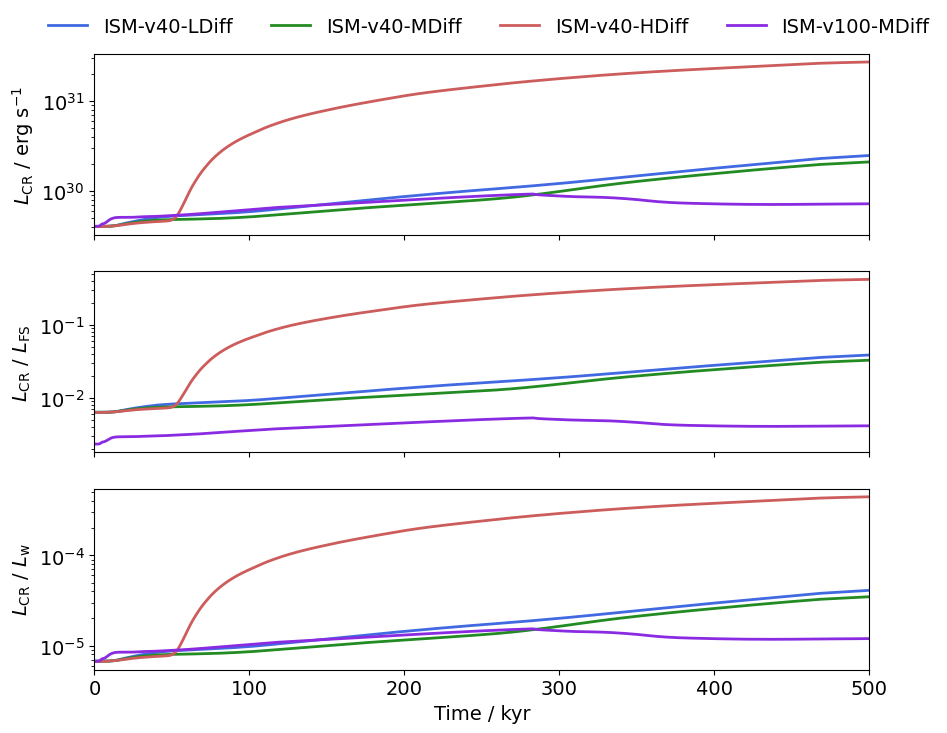

In [17]:
fig, axs = plt.subplots(3,1,figsize=(10,8), sharex=True, gridspec_kw = {'wspace':0.1})

axs = axs.flatten()

for ibs, bs_name in enumerate(bowshock_config.keys()):
    print(bs_name)
    if bs_name == "ISM-v40-MHD":
        continue
    sim_dir = os.path.join(flash_output_dir, bs_name)
    total_output_data = np.genfromtxt(os.path.join(flash_output_dir, sim_dir, "starISM.dat"),  skip_header=1)
    time1 = total_output_data[:,0] * u.s
    E_tot = total_output_data[:,5] * u.erg

    E_tot = E_tot[np.argsort(time1)]
    time1 = time1[np.argsort(time1)]

    # claculate the difference
    dEtot = np.diff(E_tot)
    dt1 = np.diff(time1)

    # L_tot = np.abs(np.gradient(E_tot, time1))
    L_tot = np.abs(dEtot) / dt1
    time_tot_centers = 0.5 * (time1[:-1] + time1[1:])

    time_data = np.genfromtxt(os.path.join(flash_output_dir, sim_dir, "CRsources.dat"), delimiter=" ", skip_header=1)
    time_CRs = time_data[:,0] * u.s
    deltat_crs = time_data[:,2] * u.s
    # Ecrs_tot = time_data[:,4] * u.erg
    # Ecrs_tot = Ecrs_tot[np.argsort(time_CRs)]
    L_CRs = time_data[:,6] * u.erg / u.s
    deltat_crs = deltat_crs[np.argsort(time_CRs)]
    L_CRs = np.abs(L_CRs[np.argsort(time_CRs)])
    time_CRs = time_CRs[np.argsort(time_CRs)]

    # axs[0].semilogy(time_tot_centers.to(u.kyr), L_tot, ls='-', lw=2.0, color=bowshock_config[bs_name]['color'])
    axs[0].semilogy(time_CRs.to(u.kyr), L_CRs, ls='-', lw=2.0, color=bowshock_config[bs_name]['color'], label=bs_name)



    L_fs = get_forward_shock_luminosity(bs_name)
    # axs[0].axhline(L_fs.value, lw=2.0, ls=':', color='k', label='Kinetic Luminosity (approx)')
    # axs[0].axhline(Lwind.value, lw=2.0, ls="-.", color='k', label='Wind Luminosity')

    axs[0].set_ylabel(r"$L_\mathrm{CR}$ / erg s$^{-1}$", fontsize=14)

    axs[1].semilogy(time_CRs.to(u.kyr), L_CRs / L_fs, ls='-', lw=2.0, color=bowshock_config[bs_name]['color'], label=bs_name)

    axs[1].set_ylabel(r"$L_\mathrm{CR}$ / $L_\mathrm{FS}$", fontsize=14)
    # axs[1].set_ylim(0,1)


    axs[2].semilogy(time_CRs.to(u.kyr), L_CRs / Lwind, ls='-', lw=2.0, color=bowshock_config[bs_name]['color'], label=bs_name)

    axs[2].set_ylabel(r"$L_\mathrm{CR}$ / $L_\mathrm{w}$", fontsize=14)
    # axs[2].set_ylim(0,1)

    axs[-1].set_xlabel("Time / kyr", fontsize=14)

    for ax in axs:
        ax.set_xlim(0, 500)
        ax.tick_params(axis='both', labelsize=14)

    axs[0].legend(
        bbox_to_anchor=[1.1, 1.3],
        fontsize=14,
        ncols=4,
        frameon=False
    )


Compare between old version and new version of CR acceleration by comparing cumulative energy vs time

Text(0.5, 1.0, 'CR Luminosity for ISM-v100-MDiff')

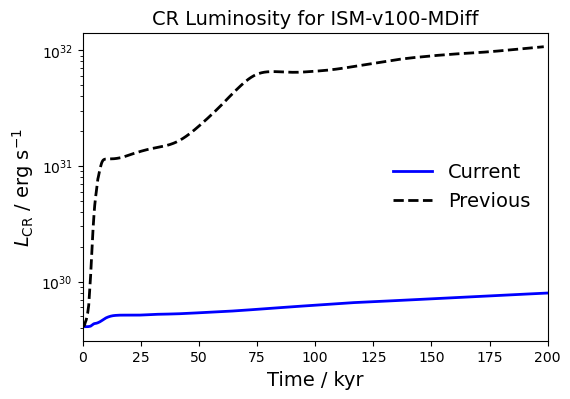

In [22]:
fig, ax = plt.subplots(figsize=(6,4))

time_data = np.genfromtxt(os.path.join(flash_output_dir, "ISM-v100-MDiff", "CRsources.dat"), delimiter=" ", skip_header=1)
time_CRs = time_data[:,0] * u.s
deltat_crs = time_data[:,2] * u.s
# Ecrs_tot = time_data[:,4] * u.erg
# Ecrs_tot = Ecrs_tot[np.argsort(time_CRs)]
L_CRs = time_data[:,6] * u.erg / u.s
deltat_crs = deltat_crs[np.argsort(time_CRs)]
L_CRs = np.abs(L_CRs[np.argsort(time_CRs)])
time_CRs = time_CRs[np.argsort(time_CRs)]

ax.semilogy(time_CRs.to(u.kyr), L_CRs, ls='-', lw=2.0, color='b', label='Current')

time_data = np.genfromtxt(os.path.join("/home/kwatanabe/Projects/cr-bowshocks/outputs_new", "ISM_v100_CR", "CRsources.dat"), delimiter=" ", skip_header=1)
time_CRs = time_data[:,0] * u.s
deltat_crs = time_data[:,2] * u.s
# Ecrs_tot = time_data[:,4] * u.erg
# Ecrs_tot = Ecrs_tot[np.argsort(time_CRs)]
L_CRs = time_data[:,6] * u.erg / u.s
deltat_crs = deltat_crs[np.argsort(time_CRs)]
L_CRs = np.abs(L_CRs[np.argsort(time_CRs)])
time_CRs = time_CRs[np.argsort(time_CRs)]

ax.semilogy(time_CRs.to(u.kyr), L_CRs, ls='--', lw=2.0, color='k', label='Previous')

ax.legend(fontsize=14, frameon=False)
ax.set_xlabel('Time / kyr', fontsize=14)
ax.set_ylabel(r"$L_\mathrm{CR}$ / erg s$^{-1}$", fontsize=14)

ax.set_xlim(0, 200)
ax.set_title("CR Luminosity for ISM-v100-MDiff", fontsize=14)